In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


Pandas: 3.0.6
NumPy: 2.5.4


In [2]:
wildfires_df = pd.read_csv('/Users/marianabutarov/Data_Science/Wildfire/Code/wildfires_clean.csv')

In [3]:
birds_df = pd.read_csv('/Users/marianabutarov/Data_Science/Wildfire/Code/birds_clean.csv')

In [4]:
wildfires_df.head()

,fire_id,date,cause,state,region,year,month
0,05-511038-05,2005-01-02,Miscellaneous,OR,West,2005,1
1,05-723036-05,2005-01-08,Lightning,OR,South,2005,1
2,05-531088-05,2005-02-15,Debris Burning,OR,North,2005,2
3,05-552014-05,2005-02-20,Debris Burning,OR,North,2005,2
4,05-581075-05,2005-02-23,Debris Burning,OR,North,2005,2


In [5]:
wildfires_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 58961 entries, 0 to 58960
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   fire_id  58961 non-null  str  
 1   date     58961 non-null  str  
 2   cause    58961 non-null  str  
 3   state    58961 non-null  str  
 4   region   58961 non-null  str  
 5   year     58961 non-null  int64
 6   month    58961 non-null  int64
dtypes: int64(2), str(5)
memory usage: 3.1 MB


In [6]:
birds_df.head()

,observation date,species,state,region,year,month,observation count
0,2005-01-01,American Crow,CA,East,2005,1,3
1,2005-01-01,American Kestrel,CA,East,2005,1,1
2,2005-01-01,American Robin,CA,East,2005,1,32
3,2005-01-01,Downy Woodpecker,CA,East,2005,1,3
4,2005-01-01,Mourning Dove,CA,East,2005,1,8


In [7]:
birds_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 758398 entries, 0 to 758397
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   observation date   758398 non-null  str  
 1   species            758398 non-null  str  
 2   state              758398 non-null  str  
 3   region             758398 non-null  str  
 4   year               758398 non-null  int64
 5   month              758398 non-null  int64
 6   observation count  758398 non-null  int64
dtypes: int64(3), str(4)
memory usage: 40.5 MB


In [8]:
birds_df["observation date"] = pd.to_datetime(birds_df["observation date"])
wildfires_df["date"] = pd.to_datetime(wildfires_df["date"])

In [25]:
wildfires_daily = wildfires_df.copy()

In [27]:
wildfires_daily = wildfires_daily.drop(columns=["cause"])

In [29]:
wildfires_daily = (
    wildfires_daily.groupby(
        ["year", "month", "date", "state", "region"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "fire count"})
)

In [31]:
wildfires_daily.head(50)

,year,month,date,state,region,fire count
0,2005,1,2005-01-02,OR,West,1
1,2005,1,2005-01-08,OR,South,1
2,2005,2,2005-02-15,OR,North,1
3,2005,2,2005-02-20,OR,North,1
4,2005,2,2005-02-23,OR,North,1
5,2005,2,2005-02-23,OR,West,1
6,2005,2,2005-02-27,OR,North,1
7,2005,2,2005-02-27,OR,South,2
8,2005,3,2005-03-04,OR,South,1
9,2005,3,2005-03-06,OR,South,2


In [33]:
combined = birds_df.merge(
    wildfires_daily[["date", "state", "region", "fire count"]],
    left_on=["observation date", "state", "region"],
    right_on=["date", "state", "region"],
    how="left",
    validate="many_to_one"
)

In [35]:
combined.head(50)

,observation date,species,state,region,year,month,observation count,date,fire count
0,2005-01-01,American Crow,CA,East,2005,1,3,NaT,NaN
1,2005-01-01,American Kestrel,CA,East,2005,1,1,NaT,NaN
2,2005-01-01,American Robin,CA,East,2005,1,32,NaT,NaN
3,2005-01-01,Downy Woodpecker,CA,East,2005,1,3,NaT,NaN
4,2005-01-01,Mourning Dove,CA,East,2005,1,8,NaT,NaN
5,2005-01-01,Northern Flicker,CA,East,2005,1,23,NaT,NaN
6,2005-01-01,Red-tailed Hawk,CA,East,2005,1,7,NaT,NaN
7,2005-01-01,Red-winged Blackbird,CA,East,2005,1,2,NaT,NaN
8,2005-01-01,Song Sparrow,CA,East,2005,1,2,NaT,NaN
9,2005-01-01,American Crow,CA,North,2005,1,2,NaT,NaN


In [37]:
combined = combined.drop(columns=["date"])

combined = combined.rename(columns={
    "observation count": "bird count"
})

In [39]:
combined.head(50)

,observation date,species,state,region,year,month,bird count,fire count
0,2005-01-01,American Crow,CA,East,2005,1,3,NaN
1,2005-01-01,American Kestrel,CA,East,2005,1,1,NaN
2,2005-01-01,American Robin,CA,East,2005,1,32,NaN
3,2005-01-01,Downy Woodpecker,CA,East,2005,1,3,NaN
4,2005-01-01,Mourning Dove,CA,East,2005,1,8,NaN
5,2005-01-01,Northern Flicker,CA,East,2005,1,23,NaN
6,2005-01-01,Red-tailed Hawk,CA,East,2005,1,7,NaN
7,2005-01-01,Red-winged Blackbird,CA,East,2005,1,2,NaN
8,2005-01-01,Song Sparrow,CA,East,2005,1,2,NaN
9,2005-01-01,American Crow,CA,North,2005,1,2,NaN


In [41]:
print("Total rows:", len(combined))
print("Rows with matching fires:", combined["fire count"].notna().sum())
print("Rows without matching fires:", combined["fire count"].isna().sum())

Total rows: 758398
Rows with matching fires: 200667
Rows without matching fires: 557731


In [43]:
combined["fire count"] = combined["fire count"].fillna(0).astype(int)

In [45]:
combined[combined["fire count"] > 0 ].head(50)

,observation date,species,state,region,year,month,bird count,fire count
153,2005-01-02,American Crow,OR,West,2005,1,0,1
154,2005-01-02,American Robin,OR,West,2005,1,300,1
155,2005-01-02,Dark-eyed Junco,OR,West,2005,1,0,1
156,2005-01-02,Downy Woodpecker,OR,West,2005,1,0,1
157,2005-01-02,Mourning Dove,OR,West,2005,1,0,1
158,2005-01-02,Northern Flicker,OR,West,2005,1,1,1
159,2005-01-02,Red-tailed Hawk,OR,West,2005,1,2,1
160,2005-01-02,Song Sparrow,OR,West,2005,1,0,1
514,2005-01-08,Dark-eyed Junco,OR,South,2005,1,22,1
515,2005-01-08,Song Sparrow,OR,South,2005,1,1,1


In [47]:
combined

,observation date,species,state,region,year,month,bird count,fire count
0,2005-01-01,American Crow,CA,East,2005,1,3,0
1,2005-01-01,American Kestrel,CA,East,2005,1,1,0
2,2005-01-01,American Robin,CA,East,2005,1,32,0
3,2005-01-01,Downy Woodpecker,CA,East,2005,1,3,0
4,2005-01-01,Mourning Dove,CA,East,2005,1,8,0
...,...,...,...,...,...,...,...,...
758393,2025-12-31,Downy Woodpecker,WA,West,2025,12,124,0
758394,2025-12-31,Mourning Dove,WA,West,2025,12,321,0
758395,2025-12-31,Northern Flicker,WA,West,2025,12,384,0
758396,2025-12-31,Red-tailed Hawk,WA,West,2025,12,128,0


In [49]:
combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 758398 entries, 0 to 758397
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   observation date  758398 non-null  datetime64[us]
 1   species           758398 non-null  str           
 2   state             758398 non-null  str           
 3   region            758398 non-null  str           
 4   year              758398 non-null  int64         
 5   month             758398 non-null  int64         
 6   bird count        758398 non-null  int64         
 7   fire count        758398 non-null  int64         
dtypes: datetime64[us](1), int64(4), str(3)
memory usage: 46.3 MB


In [51]:
combined.to_csv('wildfires_birds.csv', encoding='utf-8-sig', index=False)

In [68]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Wildfires_birds.csv')

In [4]:
df.head()

,observation date,species,state,region,year,month,bird count,fire count
0,2005-01-01,American Crow,CA,East,2005,1,3,0
1,2005-01-01,American Crow,CA,North,2005,1,2,0
2,2005-01-01,American Crow,CA,South,2005,1,103,0
3,2005-01-01,American Crow,CA,West,2005,1,77,0
4,2005-01-01,American Kestrel,CA,East,2005,1,1,0


In [8]:
df['species'].unique()

<ArrowStringArray>
[       'American Crow',     'American Kestrel',       'American Robin',
     'Downy Woodpecker',        'Mourning Dove',     'Northern Flicker',
      'Red-tailed Hawk', 'Red-winged Blackbird',         'Song Sparrow',
      'Dark-eyed Junco']
Length: 10, dtype: str

In [53]:
wildfire_dates = df[df['fire count'] > 0]
wildfire_dates

,observation date,species,state,region,year,month,bird count,fire count
1882,2005-03-15,American Crow,CA,North,2005,3,2,1
1885,2005-03-15,American Kestrel,CA,North,2005,3,10,1
1888,2005-03-15,American Robin,CA,North,2005,3,5,1
1891,2005-03-15,Downy Woodpecker,CA,North,2005,3,0,1
1893,2005-03-15,Mourning Dove,CA,North,2005,3,4,1
...,...,...,...,...,...,...,...,...
757982,2025-12-14,Downy Woodpecker,WA,West,2025,12,317,1
757985,2025-12-14,Mourning Dove,WA,West,2025,12,321,1
757989,2025-12-14,Northern Flicker,WA,West,2025,12,1623,1
757993,2025-12-14,Red-tailed Hawk,WA,West,2025,12,220,1


Calculating the monthly average number of observations for each state, region, and species.

In [30]:
monthly_averages = df[['species', 'state', 'region', 'month', 'bird count']].groupby(['species', 'state', 'region', 'month']).mean()

In [55]:
df['monthly_ave_obs'] = df.groupby(['species', 'state', 'region', 'month'])['bird count'].transform('mean')

In [56]:
df.head(5)

,observation date,species,state,region,year,month,bird count,fire count,monthly_ave_obs
0,2005-01-01,American Crow,CA,East,2005,1,3,0,141.616114
1,2005-01-01,American Crow,CA,North,2005,1,2,0,89.978355
2,2005-01-01,American Crow,CA,South,2005,1,103,0,1343.780242
3,2005-01-01,American Crow,CA,West,2005,1,77,0,1086.022222
4,2005-01-01,American Kestrel,CA,East,2005,1,1,0,32.521968


## Let's look at a specific fire. The Carlton complext fire in 2014 was one of the largest fires in WA state history. It took place on July, 14th 2014 in Okanogan County, WA.

In [84]:
Carlton_Fire = df[(df['state'] == 'WA') & (df['region'] == 'North')
    & (df['year'] == 2014) & (df['month'] == 7)]

In [101]:
cf_dayonly = Carlton_Fire[Carlton_Fire['observation date'] == "2014-07-14"][['species', 'bird count', 'monthly_ave_obs']]

<Figure size 640x480 with 0 Axes>

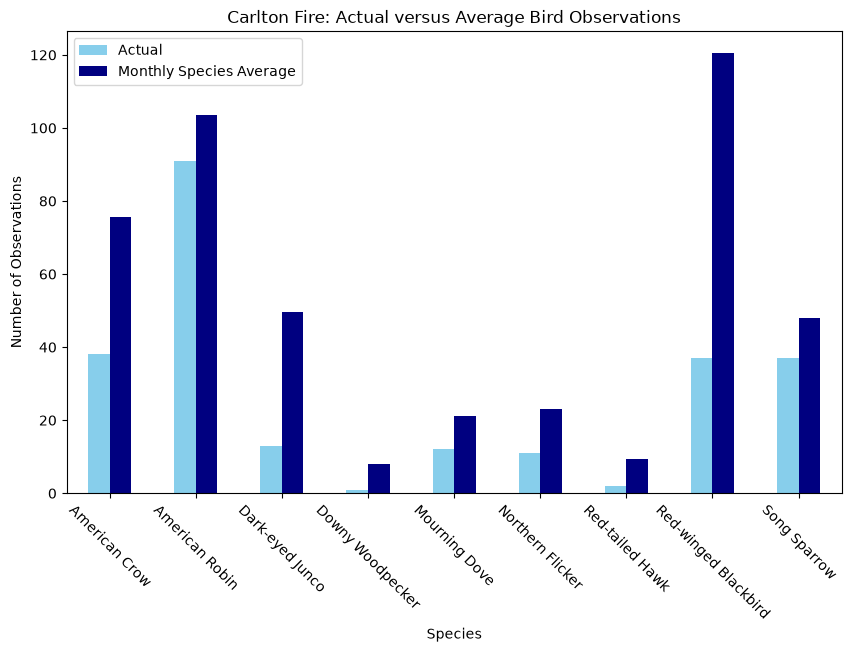

In [152]:
plt.figure()

plot_df = cf_dayonly.set_index('species')[['bird count', 'monthly_ave_obs']]
plot_df.plot(kind='bar', figsize=(10, 6), color=['skyblue', 'navy'])

plt.title('Carlton Fire: Actual versus Average Bird Observations')
plt.ylabel('Number of Observations')
plt.xticks(rotation=-45)
plt.xlabel('Species')
plt.legend(['Actual', 'Monthly Species Average'])

plt.savefig('fig5.png', bbox_inches='tight')
plt.show()

The dataset was filtered to only show observations on the day of the Carlton Fire, 2014-07-14 in the north region of Washington. This chart depicts the actual sightings per species and the average sightings for that time of year. Each species shows a difference between the actual and average observations.

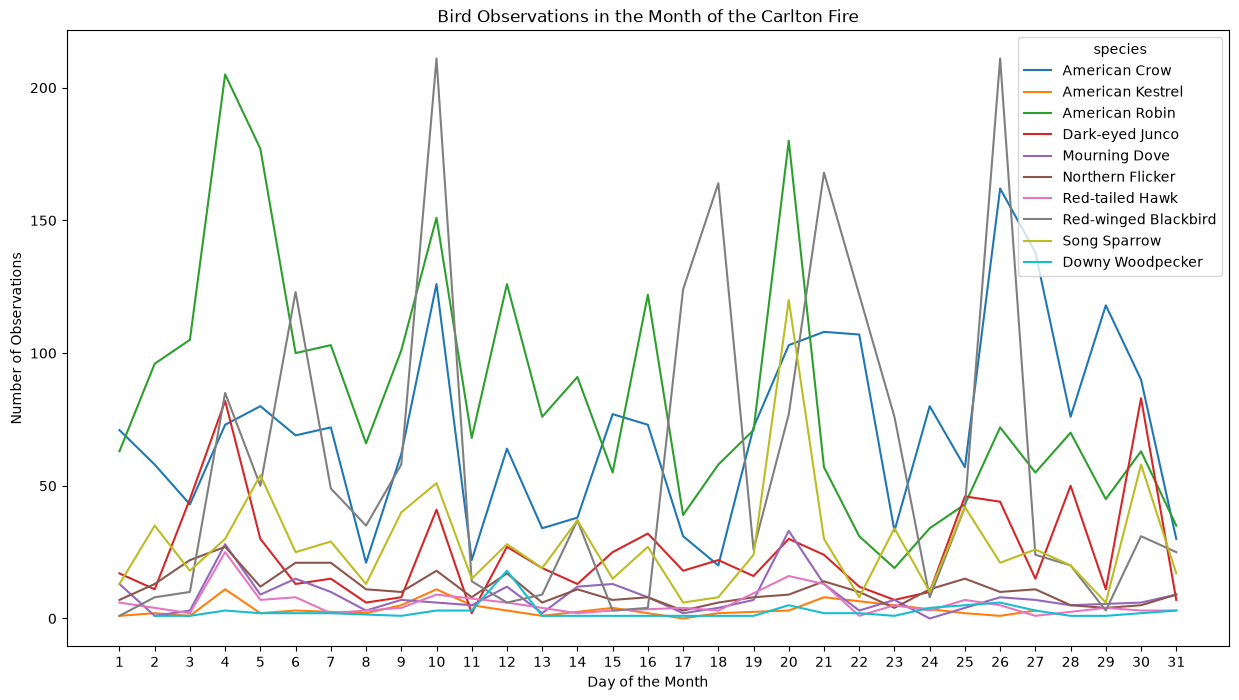

In [154]:
plt.figure(figsize=(15, 8))

sns.lineplot(data=Carlton_Fire, x='observation date', y='bird count', hue='species')
plt.xlabel('Day of the Month')
plt.ylabel('Number of Observations')
plt.xticks(ticks=['2014-07-01', '2014-07-02', '2014-07-03', '2014-07-04', '2014-07-05', '2014-07-06', '2014-07-07', '2014-07-08', '2014-07-09', '2014-07-10', '2014-07-11', '2014-07-12', '2014-07-13', '2014-07-14', '2014-07-15', '2014-07-16', '2014-07-17', '2014-07-18', '2014-07-19', '2014-07-20', '2014-07-21', '2014-07-22', '2014-07-23', '2014-07-24', '2014-07-25', '2014-07-26', '2014-07-27', '2014-07-28', '2014-07-29', '2014-07-30', '2014-07-31'], 
           labels=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
plt.title('Bird Observations in the Month of the Carlton Fire')

plt.savefig('fig6.png', bbox_inches='tight')

plt.show()

Some initial modeling

In [168]:
AmericanCrow_WA = df[(df['state'] == 'WA') & (df['species'] == 'American Crow')]

In [169]:
AmericanCrow_WA.describe()

,year,month,bird count,fire count,monthly_ave_obs
count,25902.000000,25902.000000,25902.000000,25902.000000,25902.000000
mean,2014.941510,6.405837,449.162381,1.009536,449.162381
std,5.478186,3.414766,1235.839477,2.322487,675.335913
min,2005.000000,1.000000,0.000000,0.000000,17.726862
25%,2010.000000,3.000000,17.000000,0.000000,53.182039
50%,2015.000000,6.000000,70.000000,0.000000,105.123939
75%,2020.000000,9.000000,229.000000,1.000000,776.862903
max,2024.000000,12.000000,39146.000000,86.000000,2447.857605


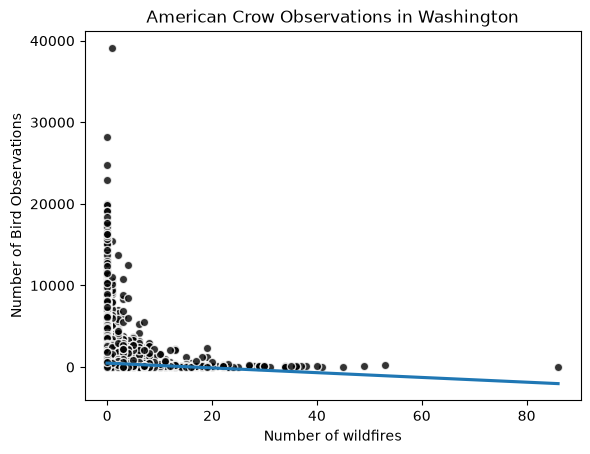

In [174]:
plt.figure()

sns.regplot(data=AmericanCrow_WA,
            x='fire count',
            y='bird count',
            ci=False,
            scatter_kws = {'color': 'black', 'edgecolors': 'white'})
plt.xlabel('Number of wildfires')
plt.ylabel('Number of Bird Observations')
plt.title('American Crow Observations in Washington')

plt.savefig('figure7.png', bbox_inches='tight')
plt.show()